In [1]:
import PyDSTool as dst
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="Modelling_the_Cell_Membrane_Potential")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    "Cm": 1,
    "gK": 0.3,
    "gNa" : 0.015,
    "EK" : -75,
    "ENa" : 55,
    "IP" : 0.5
}

# Define aux functions
fnspecs = {
    "IK": (['V'], "gK*(V - EK)"),
    "INa": (['V'], "gNa*(V - ENa)"),
}


# Define the ODEs.
varspecs = {
    "V": "1/Cm * -1*(IK(V) + INa(V) + IP)"
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "V": 0,
}

# Define a domain for V. It is needed when finding steady states.
domain = {
    "V": [-70, 0],
}


DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...


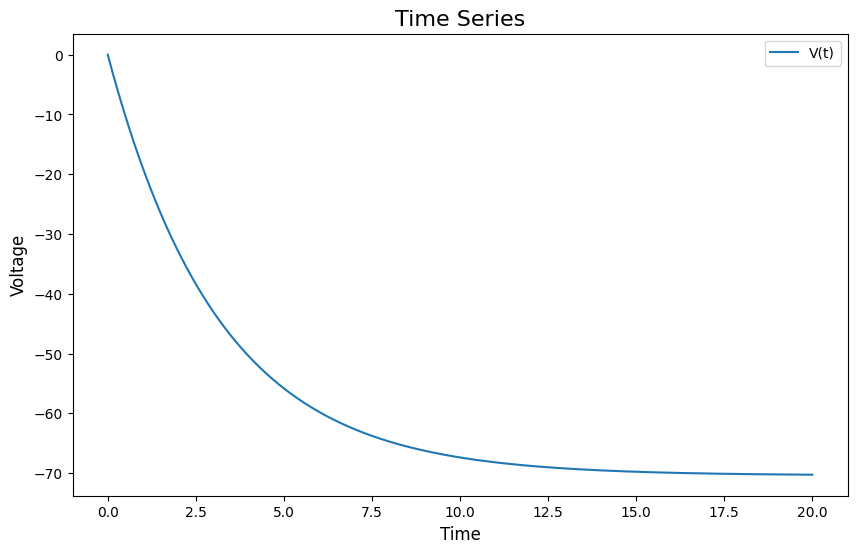

{'V': array([-70.3968254])}


In [3]:
# This module is used to plot phaseplanes and nullclines
from PyDSTool.Toolbox import phaseplane as pp
# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
# Define the range of time.
ode_sys.set(tdata=[0, 20])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fig_1, ax_1 = plt.subplots(figsize=(10, 6))
ax_1.plot(points['t'], points['V'], label='V(t)')
ax_1.set_title('Time Series', fontsize=16)
ax_1.set_xlabel('Time', fontsize=12)
ax_1.set_ylabel('Voltage', fontsize=12)
plt.legend()
plt.show()

# Now find the steady state and compare it with the analyical solution
fp_coord = pp.find_fixedpoints(ode_sys, n=4, eps=1e-8)[0]
print(fp_coord)

The new resting potential is given by $$\begin{align*}I_K+I_{Na}+I_P=0& \implies g_K(V-E_K)+g_{Na}(V-E_{Na})+I_P=0\\ &\implies V=\dfrac{g_KE_K+G_{Na}E_{Na}-I_P}{g_K+g_{Na}}.\end{align*}$$

Hence, the analytical solution is given below in the code, which does coincide to the computed FP.

In [4]:
V_actual = (0.3 * -75 + 0.015 * 55 - 0.5) / (0.3 + 0.015)
V_actual

-70.39682539682539

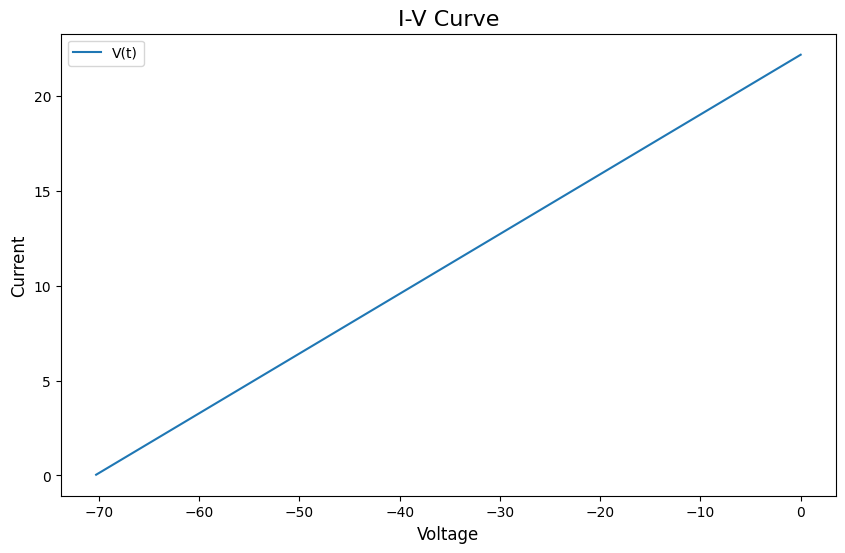

In [5]:
# Now plot the I-V curve. We have previously integrated the system so we have the potential values.
# We can define the curent by using lambda expressions. lambda variables : expression.
I_k = lambda V: pars["gK"] * (V - pars["EK"])
I_Na = lambda V: pars["gNa"] * (V - pars["ENa"])
I_P = 0.5
I_ion = lambda V: I_k(V) + I_Na(V) + I_P

fig_2, ax_2 = plt.subplots(figsize=(10, 6))
ax_2.plot(points["V"], I_ion(points["V"]), label='V(t)')
ax_2.set_title('I-V Curve', fontsize=16)
ax_2.set_xlabel('Voltage', fontsize=12)
ax_2.set_ylabel('Current', fontsize=12)
plt.legend()
plt.show()

It seems to be a shift to the left by $I_P$. Essentially, it makes the inside of the cell more negative in terms of voltage, and hence it can trigger an action potential to be fired.

Computing continuation curve in parameter Iapp...

Checking...
  |q| = 1.000000
  <p,q> = 1.000000
  |Aq| = 0.000000
  |transpose(A)p| = 0.000000

LP Point found 
0 : 
V  =  13.806542306640205
Iapp  =  94.49639256284979

Eigenvalues = 

     (0.000000,0.000000)


a = 0.17042626687668871


Checking...
  |q| = 1.000000
  <p,q> = 1.000000
  |Aq| = 0.000000
  |transpose(A)p| = 0.000000

LP Point found 
0 : 
V  =  23.660713041603895
Iapp  =  83.07341622307953

Eigenvalues = 

     (-0.000000,0.000000)


a = 0.29979981874816986



Text(0, 0.5, 'Voltage')

<Figure size 800x500 with 0 Axes>

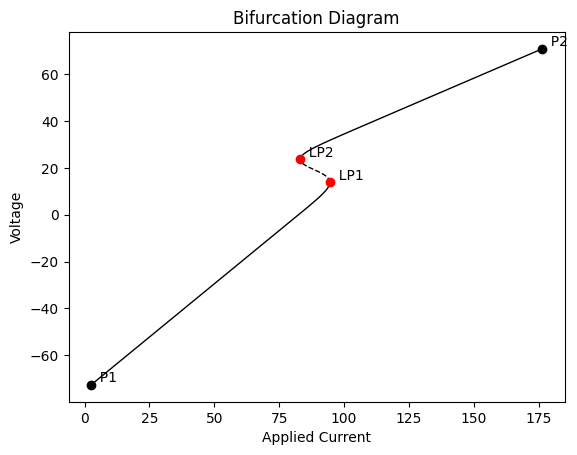

In [6]:
import PyDSTool as dst
import matplotlib.pyplot as plt

# New model
DSargs = dst.args(name="Excitable_Cell_Model")

pars = {
    "Cm" : 1,
    "gbNa" : 0.5,
    "Vth" : 20,
    "Vs" : 5,
    "gK" : 1.1,
    "EK" : -75,  
    "ENa" : 55,
    "Iapp" : 0
}

fnspecs = {
    "gNa" : (['V'], "gbNa * (1 + tanh((V - Vth) / Vs))")
}

varspecs = {
    "V": "(1/Cm) * (-1 * (gK * (V - EK) + gNa(V) * (V - ENa)) + Iapp)"
}

ics = {
    "V": -70, 
}

domain = {
    "Iapp" : [50, 150]
}

DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

# Continuation Curve
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
PC = dst.ContClass(ode_sys)

PCargs = dst.args(name="EQ1", type="EP-C")
PCargs.freepars = ["Iapp"]
PCargs.MaxNumPoints = 350
PCargs.StepSize = 0.01
PCargs.MaxStepSize = 0.75
PCargs.MinStepSize = 1e-5
PCargs.LocBifPoints = ["LP"]
PCargs.verbosity = 2
PCargs.SaveEigen = True
PC.newCurve(PCargs)

print("Computing continuation curve in parameter Iapp...")
PC["EQ1"].forward()
plt.figure(figsize=(8, 5))
PC["EQ1"].display(("Iapp", "V"), stability=True, figure = 3)
plt.title("Bifurcation Diagram")
plt.xlabel("Applied Current")
plt.ylabel("Voltage")

# Discussion
The applied current is roughly around $I_1=83$ and $I_2=94$ based on the LP results.

The lower stable region represents the neuron being at rest, before having the action potential triggered; the upper stable region represents the neuron firing the action potential, or being in a state of persistent activation.

If we start from $I_{app}=0$, the voltage will follow the lower branch until it hits the first bifurcation point $LP1$, after which it will jump to the next stable region (i.e., hysteresis) meaning it will have fired an impulse/action potential.